# Pregunta 2 Deconvolucion de Wiener y Tikhonov iterativo

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

Imagen ideal: (256, 256); rango [0.000, 1.000]
PSF original: (15, 15); suma=1.000000; rango [0.000, 0.028]


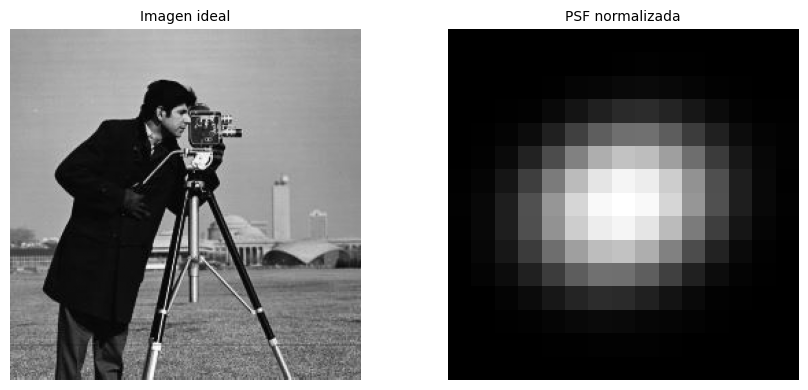

In [2]:
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.titlesize"] = 10

IMG_PATH = Path("img/cameraman.jpg")
PSF_PATH = Path("img/psf.png")
SEED = 2714

image = np.asarray(Image.open(IMG_PATH).convert("L"), dtype=np.float64) / 255.0
psf = np.asarray(Image.open(PSF_PATH).convert("L"), dtype=np.float64)
psf /= psf.sum()

print(f"Imagen ideal: {image.shape}; rango [{image.min():.3f}, {image.max():.3f}]")
print(f"PSF original: {psf.shape}; suma={psf.sum():.6f}; rango [{psf.min():.3f}, {psf.max():.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(image, vmin=0, vmax=1); axes[0].set_title("Imagen ideal")
axes[1].imshow(psf, vmin=0, vmax=psf.max()); axes[1].set_title("PSF normalizada")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 1. Implementacion: modelo de convolucion y construccion de H

Se escoge convolucion circular porque permite expresar exactamente el operador como una multiplicacion en frecuencia. La PSF se normaliza, se coloca en una matriz del tamano de la imagen y se desplaza con `ifftshift` para que su centro quede en el origen de la convolucion circular, asi, `H = FFT2(h)` es la respuesta en frecuencia usada tanto para degradar como para reconstruir.

H: forma=(256, 256); |H| minimo=1.996911e-06; |H| maximo=1.000000


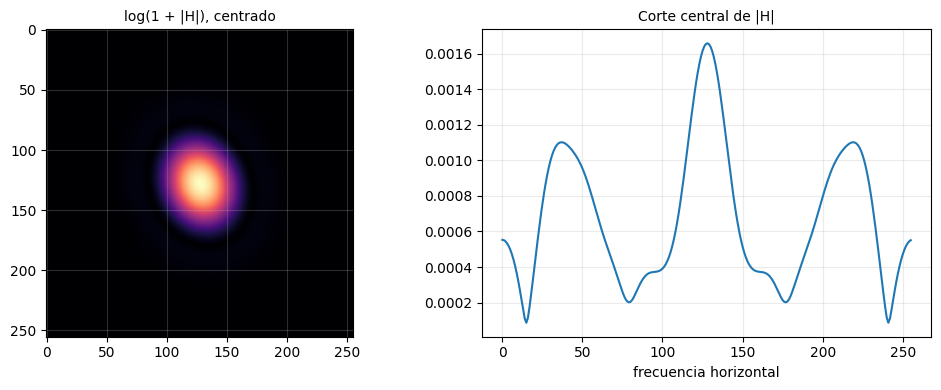

In [3]:
def psf_to_frequency(psf_array, shape):
    """Ajusta la PSF a shape y mueve su centro al origen de convolucion."""
    if psf_array.ndim != 2 or psf_array.shape[0] > shape[0] or psf_array.shape[1] > shape[1]:
        raise ValueError("La PSF debe ser 2D y no superar el tamano de la imagen")
    padded = np.zeros(shape, dtype=np.float64)
    h, w = psf_array.shape
    padded[:h, :w] = psf_array / psf_array.sum()
    center = (h // 2, w // 2)
    shifted = np.roll(padded, -center[0], axis=0)
    shifted = np.roll(shifted, -center[1], axis=1)
    return np.fft.fft2(shifted)


def apply_blur(x, H):
    return np.real(np.fft.ifft2(H * np.fft.fft2(x)))


def apply_adjoint(x, H):
    return np.real(np.fft.ifft2(np.conj(H) * np.fft.fft2(x)))


H = psf_to_frequency(psf, image.shape)
H_mag = np.abs(np.fft.fftshift(H))
print(f"H: forma={H.shape}; |H| minimo={H_mag.min():.6e}; |H| maximo={H_mag.max():.6f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(np.fft.fftshift(np.log1p(np.abs(H))), cmap="magma")
axes[0].set_title("log(1 + |H|), centrado")
axes[1].plot(np.fft.fftshift(H_mag)[image.shape[0] // 2])
axes[1].set_title("Corte central de |H|")
axes[1].set_xlabel("frecuencia horizontal")
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 2. Implementacion: observacion degradada

La observacion se genera como `y = h*x + n`, usando el mismo `H` que se utilizara en ambos metodos. Dos desviacion estandar y semilla para reproducibilidad.

sigma=0.01: observacion en [0.003, 0.901]
sigma=0.03: observacion en [-0.077, 0.936]


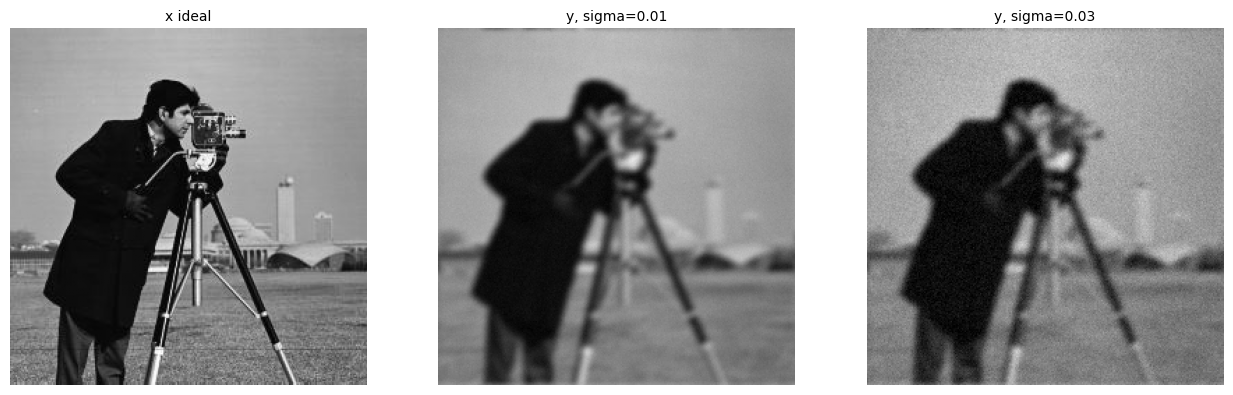

In [4]:
NOISE_LEVELS = [0.01, 0.03]
rng = np.random.default_rng(SEED)
observations = {}
for sigma in NOISE_LEVELS:
    noise = rng.normal(0.0, sigma, size=image.shape)
    observations[sigma] = apply_blur(image, H) + noise
    print(f"sigma={sigma:.2f}: observacion en [{observations[sigma].min():.3f}, {observations[sigma].max():.3f}]")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(image, vmin=0, vmax=1); axes[0].set_title("x ideal")
axes[1].imshow(observations[0.01], vmin=0, vmax=1); axes[1].set_title("y, sigma=0.01")
axes[2].imshow(observations[0.03], vmin=0, vmax=1); axes[2].set_title("y, sigma=0.03")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# Parte A Filtro de Wiener

## 3. Implementacion y experimentacion de Wiener

Se implementa directamente `X_hat = H*Y / (|H|^2 + K)`. El parametro `K` es escalar y se toma en escala logaritmica y el RMSE se calcula contra la imagen ideal.

sigma=0.01: K optimo=4.642e-03, RMSE=0.065744
sigma=0.03: K optimo=2.154e-02, RMSE=0.072766


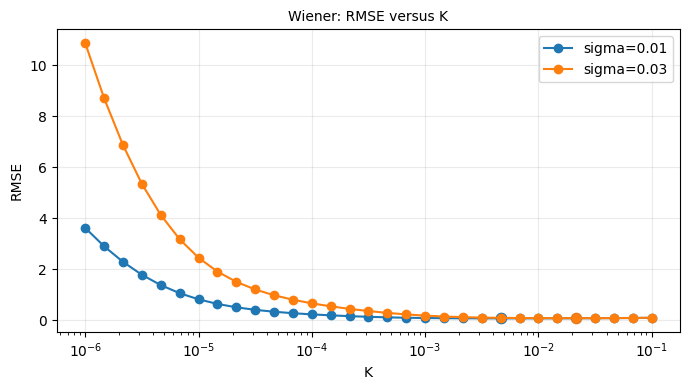

In [5]:
def wiener_deconvolution(y, H, K):
    if K <= 0:
        raise ValueError("K debe ser positivo")
    Y = np.fft.fft2(y)
    X_hat = np.conj(H) * Y / (np.abs(H) ** 2 + K)
    return np.real(np.fft.ifft2(X_hat))


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


K_VALUES = np.logspace(-6, -1, 31)
wiener_rmse = {}
wiener_best = {}
for sigma, y in observations.items():
    errors = np.array([rmse(wiener_deconvolution(y, H, K), image) for K in K_VALUES])
    wiener_rmse[sigma] = errors
    best_index = int(np.argmin(errors))
    wiener_best[sigma] = (float(K_VALUES[best_index]), float(errors[best_index]))
    print(f"sigma={sigma:.2f}: K optimo={K_VALUES[best_index]:.3e}, RMSE={errors[best_index]:.6f}")

fig, ax = plt.subplots(figsize=(7, 4))
for sigma in NOISE_LEVELS:
    ax.semilogx(K_VALUES, wiener_rmse[sigma], "o-", label=f"sigma={sigma}")
    K_best, error_best = wiener_best[sigma]
    ax.scatter([K_best], [error_best], s=55)
ax.set_xlabel("K"); ax.set_ylabel("RMSE"); ax.set_title("Wiener: RMSE versus K")
ax.grid(alpha=0.25); ax.legend(); plt.tight_layout(); plt.show()

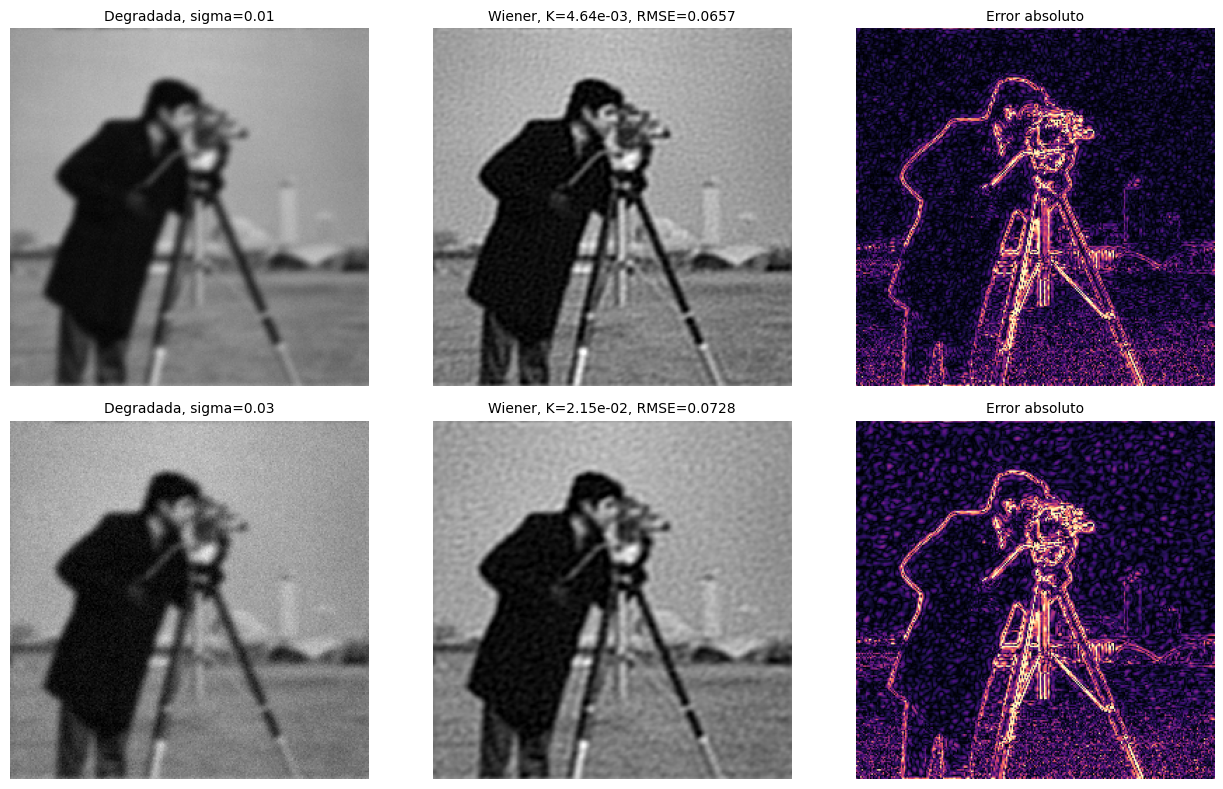

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, sigma in enumerate(NOISE_LEVELS):
    K_best, error_best = wiener_best[sigma]
    reconstruction = wiener_deconvolution(observations[sigma], H, K_best)
    axes[row, 0].imshow(observations[sigma], vmin=0, vmax=1)
    axes[row, 0].set_title(f"Degradada, sigma={sigma}")
    axes[row, 1].imshow(np.clip(reconstruction, 0, 1), vmin=0, vmax=1)
    axes[row, 1].set_title(f"Wiener, K={K_best:.2e}, RMSE={error_best:.4f}")
    axes[row, 2].imshow(np.abs(image - reconstruction), vmin=0, vmax=0.25, cmap="magma")
    axes[row, 2].set_title("Error absoluto")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

### 3.1 Wiener con PSF ligeramente incorrecta

Para estudiar el desajuste, se usa una PSF de 15x15 desplazada un pixel horizontalmente. Esta perturbacion representa un error de centrado de la PSF donde conserva la energia y el tamano, pero cambia la fase de su respuesta en frecuencia.

PSF correcta: (15, 15), PSF incorrecta: (15, 15)
RMSE correcta=0.072766
RMSE incorrecta=0.080423


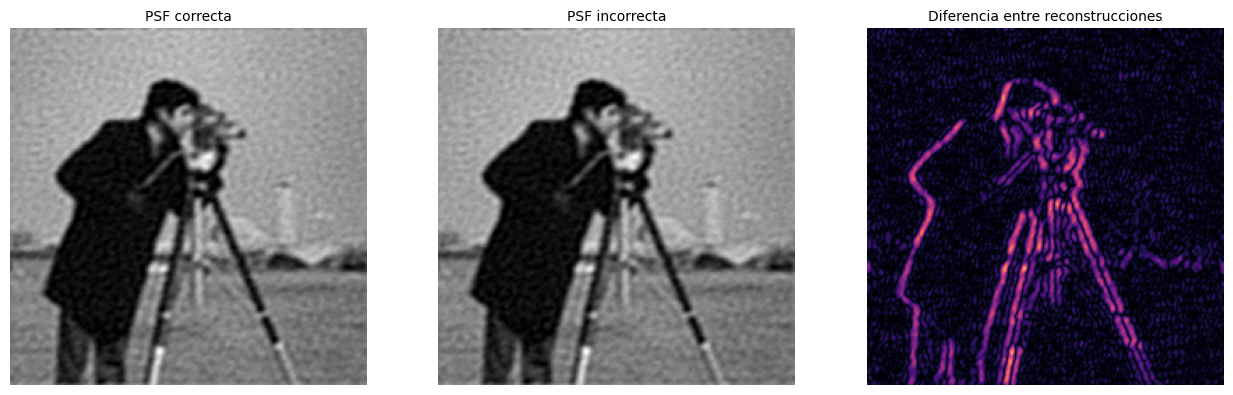

In [7]:
def perturb_psf(psf_array):
    """Introduce un error de centrado de un pixel en la PSF."""
    return np.roll(psf_array, 1, axis=1)


psf_wrong = perturb_psf(psf)
H_wrong = psf_to_frequency(psf_wrong, image.shape)
sigma = 0.03
K_best = wiener_best[sigma][0]
reconstruction_correct = wiener_deconvolution(observations[sigma], H, K_best)
reconstruction_wrong = wiener_deconvolution(observations[sigma], H_wrong, K_best)
print(f"PSF correcta: {psf.shape}, PSF incorrecta: {psf_wrong.shape}")
print(f"RMSE correcta={rmse(reconstruction_correct, image):.6f}")
print(f"RMSE incorrecta={rmse(reconstruction_wrong, image):.6f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(np.clip(reconstruction_correct, 0, 1), vmin=0, vmax=1)
axes[0].set_title("PSF correcta")
axes[1].imshow(np.clip(reconstruction_wrong, 0, 1), vmin=0, vmax=1)
axes[1].set_title("PSF incorrecta")
axes[2].imshow(np.abs(reconstruction_correct - reconstruction_wrong), vmin=0, vmax=0.25, cmap="magma")
axes[2].set_title("Diferencia entre reconstrucciones")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

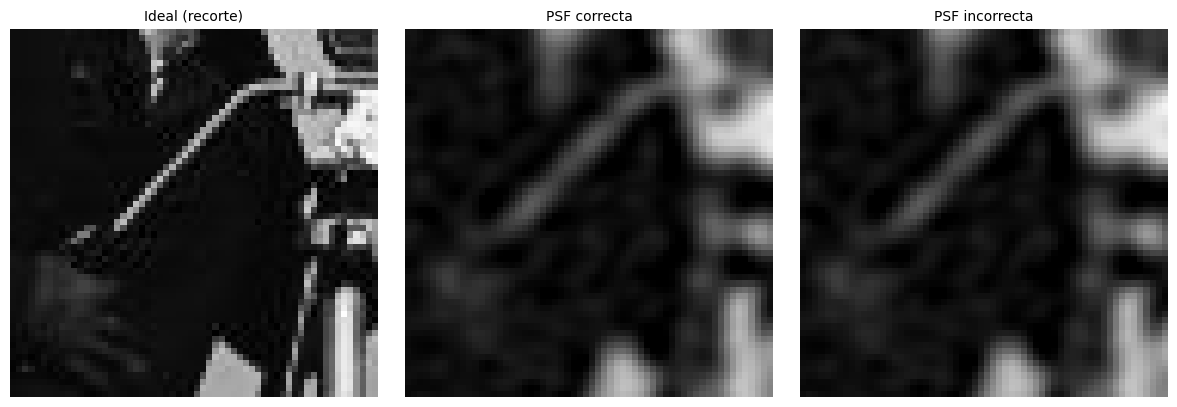

In [8]:
crop = np.s_[80:140, 80:140]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image[crop], vmin=0, vmax=1); axes[0].set_title("Ideal (recorte)")
axes[1].imshow(np.clip(reconstruction_correct[crop], 0, 1), vmin=0, vmax=1); axes[1].set_title("PSF correcta")
axes[2].imshow(np.clip(reconstruction_wrong[crop], 0, 1), vmin=0, vmax=1); axes[2].set_title("PSF incorrecta")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# Parte B — Tikhonov mediante descenso de gradiente

## 4. Implementacion del operador y del descenso

Para el problema `1/2 ||Hx-y||^2 + lambda/2 ||x||^2`, el gradiente implementado es `H^T(Hx-y) + lambda*x`. El operador adjunto `H^T` se implementa en frecuencia multiplicando por `conj(H)`, que es consistente con la convolucion circular y no supone que la PSF sea simetrica. Se registra costo, RMSE y la detencion por cambio relativo del costo.

In [9]:
def tikhonov_cost(x, y, H, lam):
    residual = apply_blur(x, H) - y
    return float(0.5 * np.sum(residual ** 2) + 0.5 * lam * np.sum(x ** 2))


def tikhonov_gradient_descent(y, H, lam, tau, max_iter=300, tol=1e-7, x0=None):
    if lam < 0 or tau <= 0 or max_iter <= 0:
        raise ValueError("lambda debe ser no negativo, tau positivo e iteraciones positivas")
    x = np.zeros_like(y) if x0 is None else np.array(x0, dtype=np.float64, copy=True)
    costs = [tikhonov_cost(x, y, H, lam)]
    rmses = [rmse(x, image)]
    for _ in range(max_iter):
        residual = apply_blur(x, H) - y
        gradient = apply_adjoint(residual, H) + lam * x
        x_next = x - tau * gradient
        next_cost = tikhonov_cost(x_next, y, H, lam)
        costs.append(next_cost)
        rmses.append(rmse(x_next, image))
        relative_change = abs(costs[-2] - costs[-1]) / max(abs(costs[-2]), 1e-12)
        x = x_next
        if relative_change < tol:
            break
    return x, np.asarray(costs), np.asarray(rmses)


def closed_form_tikhonov(y, H, lam):
    Y = np.fft.fft2(y)
    return np.real(np.fft.ifft2(np.conj(H) * Y / (np.abs(H) ** 2 + lam)))


TAU_STABLE = 1.0
LAMBDA_VALUES = [1e-5, 1e-3, 1e-2]
sigma = 0.03
y = observations[sigma]
print("Norma maxima de |H|^2:", np.abs(H).max() ** 2)
for lam in LAMBDA_VALUES:
    x_tik, costs, rmses = tikhonov_gradient_descent(y, H, lam, TAU_STABLE, max_iter=250)
    print(f"lambda={lam:.0e}: iteraciones={len(costs)-1}, costo final={costs[-1]:.4f}, RMSE final={rmses[-1]:.6f}")

Norma maxima de |H|^2: 1.0
lambda=1e-05: iteraciones=250, costo final=26.5710, RMSE final=0.093592
lambda=1e-03: iteraciones=250, costo final=35.6125, RMSE final=0.089289
lambda=1e-02: iteraciones=250, costo final=115.6207, RMSE final=0.074461


## 5. Experimentacion: lambda, paso y criterio de detencion

Se comparan tres niveles de regularizacion y dos pasos. El paso `tau=1` es estable para este operador normalizado y un paso `tau=2.2` se incluye para mostrar inestabilidad. Las curvas permiten distinguir convergencia lenta, sobre-regularizacion y divergencia.

lambda=1e-05, tau=1.0: iteraciones=120, costo=2.7019e+01, RMSE=0.078608, costo finito=True
lambda=1e-05, tau=2.2: iteraciones=120, costo=7.4174e+22, RMSE=1504590836.747424, costo finito=True
lambda=1e-03, tau=1.0: iteraciones=120, costo=3.5927e+01, RMSE=0.077679, costo finito=True
lambda=1e-03, tau=2.2: iteraciones=120, costo=1.1451e+23, RMSE=1868559147.660845, costo finito=True
lambda=1e-02, tau=1.0: iteraciones=120, costo=1.1564e+02, RMSE=0.073309, costo finito=True
lambda=1e-02, tau=2.2: iteraciones=120, costo=5.7272e+24, RMSE=13155424526.113705, costo finito=True


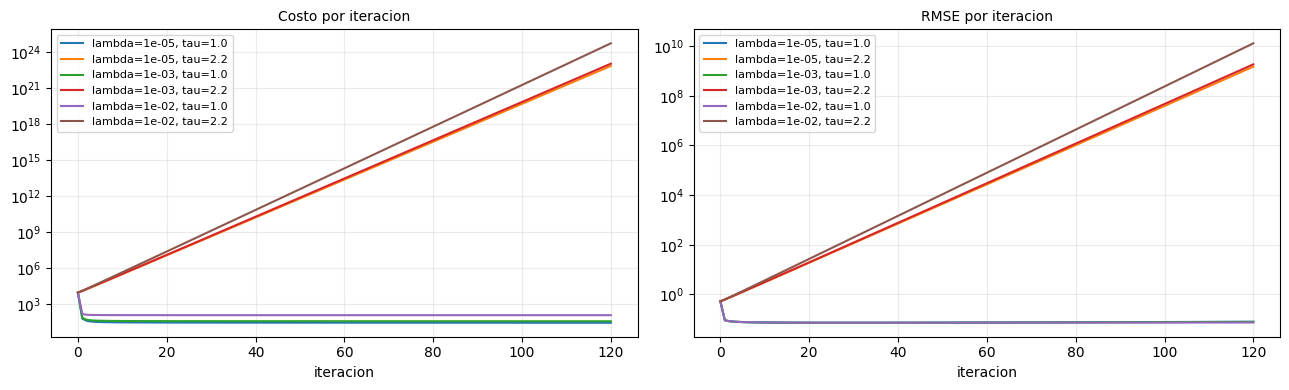

In [10]:
TAU_VALUES = [1.0, 2.2]
tikhonov_runs = {}
for lam in LAMBDA_VALUES:
    for tau in TAU_VALUES:
        result = tikhonov_gradient_descent(y, H, lam, tau, max_iter=120, tol=1e-9)
        tikhonov_runs[(lam, tau)] = result
        x_run, costs, rmses = result
        print(f"lambda={lam:.0e}, tau={tau:.1f}: iteraciones={len(costs)-1}, "
              f"costo={costs[-1]:.4e}, RMSE={rmses[-1]:.6f}, "
              f"costo finito={np.all(np.isfinite(costs))}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lam in LAMBDA_VALUES:
    for tau in TAU_VALUES:
        _, costs, rmses = tikhonov_runs[(lam, tau)]
        label = f"lambda={lam:.0e}, tau={tau}"
        axes[0].plot(costs, label=label)
        axes[1].plot(rmses, label=label)
axes[0].set_title("Costo por iteracion"); axes[0].set_xlabel("iteracion")
axes[1].set_title("RMSE por iteracion"); axes[1].set_xlabel("iteracion")
for ax in axes:
    ax.set_yscale("log"); ax.grid(alpha=0.25); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Comparacion cuantitativa con la solucion cerrada

Para `lambda=K_optimo`, la solucion cerrada de Tikhonov de orden cero tiene exactamente la forma del Wiener simplificado. Para `lambda=0`, se compara la solucion cerrada con la solucion iterativa usando el mismo operador. La igualdad numerica no es exacta porque el descenso se detiene por tolerancia y usa un numero finito de iteraciones.

lambda=2.154e-02: RMSE cerrada=0.072766, RMSE iterativa=0.072759, RMSE entre soluciones=7.834693e-05
lambda=0.000e+00: RMSE cerrada=155.536560, RMSE iterativa=0.126537, RMSE entre soluciones=1.555338e+02


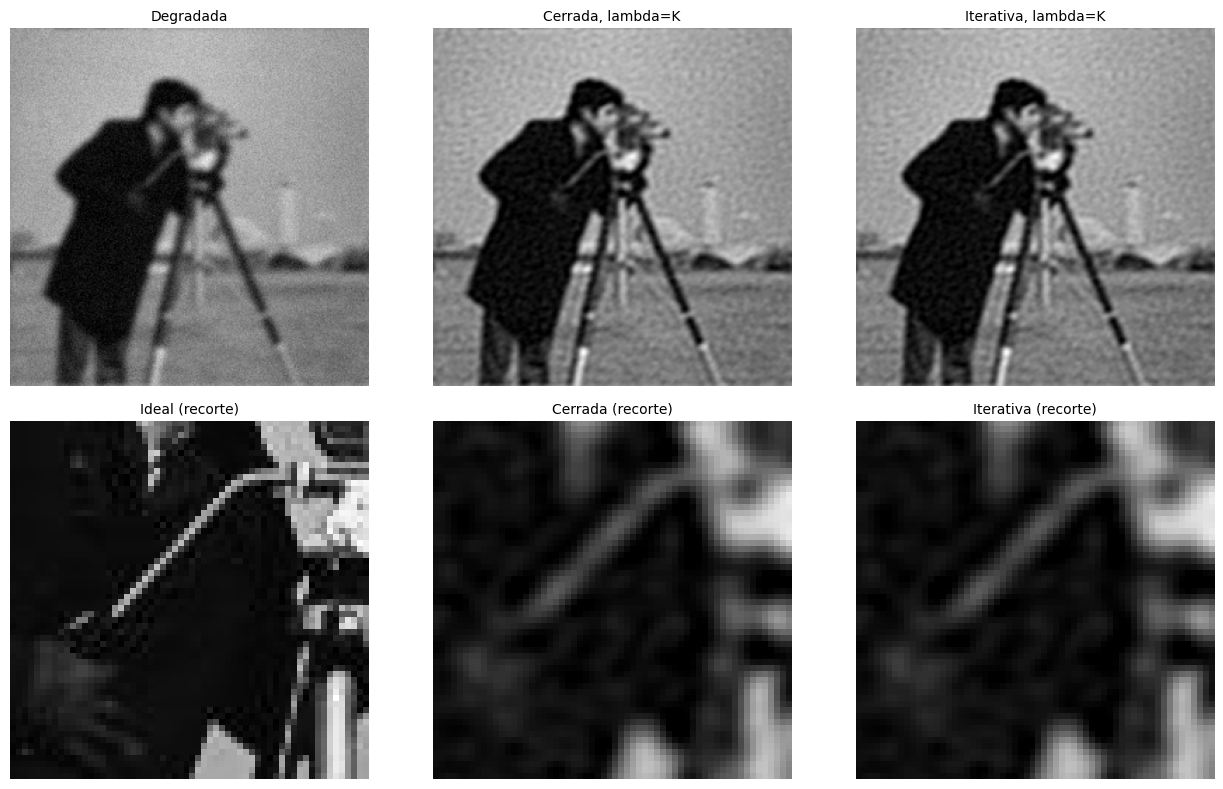

In [11]:
K_opt = wiener_best[sigma][0]
comparison = {}
for lam in [K_opt, 0.0]:
    x_closed = closed_form_tikhonov(y, H, lam)
    x_iter, costs, rmses = tikhonov_gradient_descent(y, H, lam, TAU_STABLE, max_iter=500, tol=1e-9)
    comparison[lam] = (x_closed, x_iter)
    print(f"lambda={lam:.3e}: RMSE cerrada={rmse(x_closed, image):.6f}, "
          f"RMSE iterativa={rmse(x_iter, image):.6f}, "
          f"RMSE entre soluciones={rmse(x_closed, x_iter):.6e}")

best_lam = K_opt
x_closed, x_iter = comparison[best_lam]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes[0, 0].imshow(y, vmin=0, vmax=1); axes[0, 0].set_title("Degradada")
axes[0, 1].imshow(np.clip(x_closed, 0, 1), vmin=0, vmax=1); axes[0, 1].set_title("Cerrada, lambda=K")
axes[0, 2].imshow(np.clip(x_iter, 0, 1), vmin=0, vmax=1); axes[0, 2].set_title("Iterativa, lambda=K")
axes[1, 0].imshow(image[80:140, 80:140], vmin=0, vmax=1); axes[1, 0].set_title("Ideal (recorte)")
axes[1, 1].imshow(np.clip(x_closed[80:140, 80:140], 0, 1), vmin=0, vmax=1); axes[1, 1].set_title("Cerrada (recorte)")
axes[1, 2].imshow(np.clip(x_iter[80:140, 80:140], 0, 1), vmin=0, vmax=1); axes[1, 2].set_title("Iterativa (recorte)")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()